# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

> **Sobre os números deste notebook:** os textos e a recomendação final se referem aos dados coletados em **10/10/2026** (previsão de 10 a 16/10/2026). O código funciona com qualquer coleta, mas, se o `scrape.py` for rodado em outra data, os resultados mudam e os textos deixam de bater com eles.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import LeaveOneGroupOut, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

DIR_PROC = Path("..") / "data" / "processed"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
CLASSES = ["ruim", "bom", "ótimo"]   # ordem usada em todas as tabelas e gráficos

# Na validação "deixa um dia de fora", alguns dias não têm todas as classes (o sábado
# não tem nenhuma hora "ótima"), e o sklearn avisa toda vez. O aviso é esperado.
import warnings
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [2]:
df = pd.read_csv(DIR_PROC / "dataset.csv", parse_dates=["datahora"])
print(df.shape, "| nulos:", df.isna().sum().sum())
print(df.dtypes.to_string())
df.head()

(168, 15) | nulos: 0
datahora          datetime64[us]
altura_onda_m            float64
direcao_onda                 str
vento_kmh                float64
direcao_vento                str
mare_altura_m            float64
mare_estado                  str
horas_ate_pico           float64
coeficiente                int64
idade_lua                  int64
hora                       int64
dia_semana                   str
periodo                      str
luz_do_dia                  bool
vento_do_mar                bool


,datahora,altura_onda_m,direcao_onda,vento_kmh,direcao_vento,mare_altura_m,mare_estado,horas_ate_pico,coeficiente,idade_lua,hora,dia_semana,periodo,luz_do_dia,vento_do_mar
0,2026-10-10 00:00:00,0.9,ESE,24.0,SE,1.219251,subindo,3.416667,96,29,0,sáb,madrugada,False,True
1,2026-10-10 01:00:00,1.0,ESE,24.0,SE,1.814631,subindo,2.416667,96,29,1,sáb,madrugada,False,True
2,2026-10-10 02:00:00,1.0,ESE,24.0,ESE,2.306899,subindo,1.416667,96,29,2,sáb,madrugada,False,True
3,2026-10-10 03:00:00,1.0,ESE,23.0,ESE,2.573637,subindo,0.416667,96,29,3,sáb,madrugada,False,True
4,2026-10-10 04:00:00,1.0,ESE,22.0,ESE,2.547400,descendo,5.583333,96,29,4,sáb,madrugada,False,True


O dataset chegou com as 168 horas e 15 colunas salvas na Etapa 2, sem nenhum valor nulo. A coluna datahora já veio como data, porque foi lida com parse_dates, e as colunas luz_do_dia e vento_do_mar vieram como verdadeiro ou falso.

## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

### A regra de surf

Cada hora ganha **pontos**, e os pontos viram uma classe:

| Variável | Condição | Pontos | De onde vem o número |
|---|---|---|---|
| **Luz do dia** | entre 5h e 17h | obrigatório: à noite, a hora é **ruim** direto | nascer ~5h e pôr do sol ~17h15 em outubro (dado do próprio site) |
| **Altura da onda** | ≥ 1,3 m | +2 | chute informado: para surfistas intermediários em *beach break*, 1–1,5 m é a faixa boa; 1,3 m é também o **3º quartil** dos nossos dados (só os 25% maiores) |
| | 1,0 a 1,2 m | +1 | abaixo de 1 m a onda fica fraca para surf |
| | < 1,0 m | 0 | |
| **Vento do mar (maral)** | ≤ 19 km/h | +1 | **escala Beaufort**: até 19 km/h é força 3 ("brisa fraca"); de 20 km/h em diante (força 4) aparecem os carneirinhos e o mar fica mexido |
| | 20 a 22 km/h | 0 | 22 km/h é a **mediana** do vento na janela |
| | > 22 km/h | −1 | |
| **Vento da terra (terral)** | qualquer | +2 | é o vento ideal para surf: segura a onda e alisa a parede (não aconteceu nesta semana) |
| **Maré** | entre 0,7 e 1,9 m (meia-maré) | +1 | chute informado: nos extremos a onda costuma piorar (maré seca demais quebra rasa; maré cheia demais "engole" a onda); a faixa exclui o terço mais alto e o mais baixo da amplitude |

**Classes:** até 1 ponto = **ruim** · 2 pontos = **bom** · 3 ou mais = **ótimo**.

A onda pesa mais que o vento, e o vento mais que a maré. Essa ordem de importância também é uma escolha. Os números são chutes informados, não verdades: a regra é o "professor" do modelo, e o modelo nunca vai ser melhor que ela.

In [3]:
def pontuar(linha):
    """Pontos de surf de uma hora. None = noite (não dá para surfar)."""
    if not linha["luz_do_dia"]:
        return None

    pontos = 0
    # Onda: o fator principal.
    if linha["altura_onda_m"] >= 1.3:
        pontos += 2
    elif linha["altura_onda_m"] >= 1.0:
        pontos += 1

    # Vento: terral ajuda muito; maral atrapalha mais quanto mais forte.
    if not linha["vento_do_mar"]:
        pontos += 2
    elif linha["vento_kmh"] <= 19:
        pontos += 1
    elif linha["vento_kmh"] > 22:
        pontos -= 1

    # Maré: meia-maré é melhor que os extremos.
    if 0.7 <= linha["mare_altura_m"] <= 1.9:
        pontos += 1

    return pontos


def classificar(pontos):
    if pontos is None or pd.isna(pontos) or pontos <= 1:
        return "ruim"
    return "bom" if pontos == 2 else "ótimo"


df["pontos"] = df.apply(pontuar, axis=1)
df["condicao"] = df["pontos"].map(classificar)
df[["datahora", "altura_onda_m", "vento_kmh", "mare_altura_m", "luz_do_dia", "pontos", "condicao"]].iloc[8:16]

,datahora,altura_onda_m,vento_kmh,mare_altura_m,luz_do_dia,pontos,condicao
8,2026-10-10 08:00:00,1.0,20.0,0.569673,True,1.0,ruim
9,2026-10-10 09:00:00,1.1,23.0,0.252600,True,0.0,ruim
10,2026-10-10 10:00:00,1.1,23.0,0.226666,True,0.0,ruim
11,2026-10-10 11:00:00,1.1,23.0,0.495826,True,0.0,ruim
12,2026-10-10 12:00:00,1.1,23.0,0.988971,True,1.0,ruim
13,2026-10-10 13:00:00,1.1,23.0,1.576787,True,1.0,ruim
14,2026-10-10 14:00:00,1.1,24.0,2.105134,True,0.0,ruim
15,2026-10-10 15:00:00,1.1,24.0,2.435466,True,0.0,ruim


condicao
ruim     67.3%
bom      14.3%
ótimo    18.5%
Name: count, dtype: str


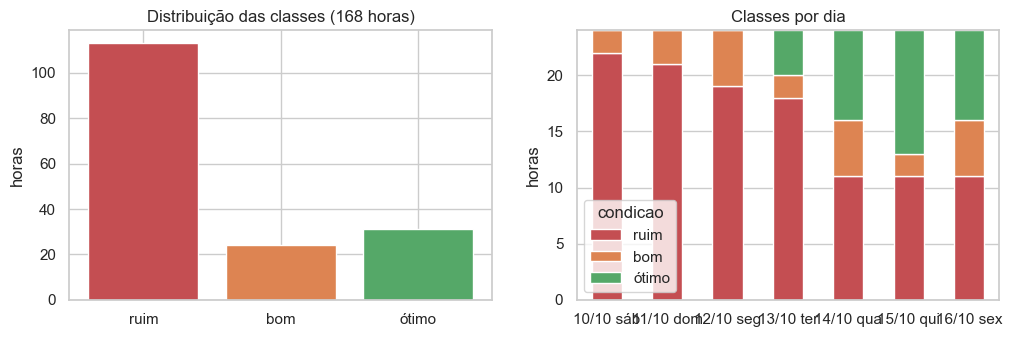

In [4]:
contagem = df["condicao"].value_counts().reindex(CLASSES)
print((contagem / len(df) * 100).round(1).astype(str) + "%")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].bar(contagem.index, contagem.values, color=["#c44e52", "#dd8452", "#55a868"])
axs[0].set(title="Distribuição das classes (168 horas)", ylabel="horas")
por_dia = pd.crosstab(df["datahora"].dt.strftime("%d/%m ") + df["dia_semana"], df["condicao"]).reindex(columns=CLASSES)
por_dia.plot(kind="bar", stacked=True, ax=axs[1], color=["#c44e52", "#dd8452", "#55a868"], rot=0)
axs[1].set(title="Classes por dia", xlabel="", ylabel="horas")
plt.show()

A maior parte das horas (67%) ficou como ruim, mas isso acontece principalmente por causa da noite, que responde por 77 das 113 horas ruins. Durante o dia, as três classes ficam mais equilibradas: 14% das horas são boas e 18% são ótimas. Não chega perto do caso em que 95% das horas caem numa classe só, mas o desbalanceamento é suficiente para a acurácia enganar, como aparece na seção 6.

O gráfico por dia já mostra como foi a semana. O sábado e o domingo (10 e 11) não tiveram nenhuma hora ótima, e as horas ótimas se concentraram entre quarta e sexta (14 a 16), quando as ondas ficaram maiores.

## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

### Escolha das features

Entraram como features a altura da onda, a velocidade e a direção do vento, a altura da maré, se ela está subindo ou descendo, as horas até o próximo pico, o coeficiente, a hora e a direção da onda.

Deixei algumas colunas de fora. A coluna luz_do_dia entregaria a resposta das horas da noite, então preferi que o modelo descobrisse isso sozinho a partir da hora. O dia da semana também ficou de fora, porque com 7 dias cada um aparece uma vez só, e o modelo poderia simplesmente decorar que quarta é bom, o que não vale para a próxima quarta. O período do dia repete a informação da hora, a idade da lua repete a do coeficiente e vento_do_mar foi verdadeiro em todas as horas, então nenhuma delas ajudaria.

É importante deixar claro que as features principais (onda, vento, maré e hora) são as mesmas variáveis usadas na regra. Por isso, o modelo não vai aprender sobre surf, e sim a imitar a regra que eu escrevi. Isso é esperado neste projeto, mas precisa ser levado em conta na hora de interpretar os resultados.

As direções da onda e do vento são texto, então precisavam virar números. Se eu usasse E = 1, ESE = 2 e SE = 3, o modelo entenderia que SE é maior que E, uma ordem que não existe. Por isso usei one-hot encoding: cada direção vira uma coluna própria, com 1 quando o vento vem daquela direção e 0 quando não vem.

In [5]:
numericas = ["altura_onda_m", "vento_kmh", "mare_altura_m", "horas_ate_pico", "coeficiente", "hora"]
categoricas = ["direcao_onda", "direcao_vento", "mare_estado"]

# One-hot: cada direção vira uma coluna 0/1 ("direcao_vento_E", "direcao_vento_SE"...).
# Assim o modelo não acha que "SE" é "maior" que "E", como aconteceria com E=1, ESE=2, SE=3.
X = pd.get_dummies(df[numericas + categoricas], columns=categoricas, dtype=int)
y = df["condicao"]
print(X.shape)
X.columns.tolist()

(168, 14)


['altura_onda_m',
 'vento_kmh',
 'mare_altura_m',
 'horas_ate_pico',
 'coeficiente',
 'hora',
 'direcao_onda_E',
 'direcao_onda_ESE',
 'direcao_vento_E',
 'direcao_vento_ENE',
 'direcao_vento_ESE',
 'direcao_vento_SE',
 'mare_estado_descendo',
 'mare_estado_subindo']

## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

### Como dividir

Não sorteei as linhas entre treino e teste. Horas vizinhas são muito parecidas, porque a onda muda devagar e a maré é contínua. Se as 13h de um dia ficassem no treino e as 14h do mesmo dia no teste, o modelo acertaria só por já ter visto uma hora quase igual, o que seria vazamento de informação e faria o modelo parecer melhor do que é.

Em vez disso, usei os 5 primeiros dias (10 a 14) para o treino e os 2 últimos (15 e 16) para o teste. Assim o teste simula o uso real: o modelo aprende com os dias anteriores e é avaliado em dias que ainda não viu.

Também não estratifiquei pelas classes. Estratificar significa sortear as linhas mantendo a mesma proporção de classes no treino e no teste, o que exigiria misturar os dias e quebraria a ordem no tempo. Preferi manter a ordem e aceitar que as proporções fiquem diferentes.

In [6]:
dia = df["datahora"].dt.date
dias = sorted(dia.unique())
treino = dia <= dias[4]          # os 5 primeiros dias da janela
teste = ~treino

X_tr, X_te, y_tr, y_te = X[treino], X[teste], y[treino], y[teste]
print(f"Treino: {len(X_tr)} horas ({dia[treino].min()} a {dia[treino].max()})")
print(f"Teste:  {len(X_te)} horas ({dia[teste].min()} a {dia[teste].max()})")
pd.DataFrame({"treino": y_tr.value_counts(), "teste": y_te.value_counts()}).reindex(CLASSES)

Treino: 120 horas (2026-10-10 a 2026-10-14)
Teste:  48 horas (2026-10-15 a 2026-10-16)


,treino,teste
condicao,,
ruim,91,22
bom,17,7
ótimo,12,19


As proporções ficaram bem diferentes entre treino e teste. O treino tem só 12 horas ótimas (10% das horas), enquanto o teste tem 19 (40%), porque as maiores ondas chegaram no fim da semana. Ou seja, o modelo vai ser testado justamente no tipo de hora que ele menos viu no treino, o que deixa o teste mais difícil, mas mais honesto.

## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

### Os modelos

Treinei três modelos. O primeiro é só uma referência: um modelo que sempre responde ruim, a classe mais comum. Ele não serve para nada sozinho, mas qualquer modelo de verdade precisa ser melhor que ele.

O segundo é uma árvore de decisão, que aprende uma sequência de perguntas sobre os dados, como "o vento é menor que 19,5 km/h?". Limitei a profundidade a 4, ou seja, no máximo 4 perguntas seguidas, para ela não decorar os dados de treino (a seção 6 mostra por que escolhi 4). Também usei class_weight="balanced", que dá mais peso às classes com menos exemplos, para o modelo não ignorar a classe ótimo só porque ela é rara.

O terceiro é o KNN, de outra família de modelos. Para classificar uma hora, ele procura as 5 horas mais parecidas no treino e vê qual classe aparece mais entre elas. Antes disso, as variáveis são padronizadas com o StandardScaler, porque sem isso o vento, com valores perto de 20, pesaria muito mais na distância do que a onda, com valores perto de 1.

In [7]:
modelos = {
    # Referência "burra": sempre chuta a classe mais comum. Serve para mostrar quanto a acurácia engana.
    "baseline (sempre 'ruim')": DummyClassifier(strategy="most_frequent"),
    # Árvore de decisão: aprende perguntas do tipo "onda >= 1.25?". Profundidade limitada para não decorar.
    "árvore de decisão": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    # KNN: olha as 5 horas mais parecidas no treino e vota. Precisa padronizar as escalas
    # (senão "vento" em km/h, com valores ~20, pesaria muito mais que "onda" em metros, ~1).
    "KNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for nome, modelo in modelos.items():
    modelo.fit(X_tr, y_tr)
print("Modelos treinados:", list(modelos))

Modelos treinados: ["baseline (sempre 'ruim')", 'árvore de decisão', 'KNN (k=5)']


## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

In [8]:
linhas = []
for nome, modelo in modelos.items():
    pred = modelo.predict(X_te)
    linhas.append({
        "modelo": nome,
        "acurácia": accuracy_score(y_te, pred),
        "acurácia balanceada": balanced_accuracy_score(y_te, pred),
        "F1 macro": f1_score(y_te, pred, average="macro"),
    })
pd.DataFrame(linhas).set_index("modelo").round(2)

,acurácia,acurácia balanceada,F1 macro
modelo,,,
baseline (sempre 'ruim'),0.46,0.33,0.21
árvore de decisão,0.52,0.59,0.52
KNN (k=5),0.58,0.61,0.56


A acurácia sozinha não é suficiente aqui. Ela mede a fração de acertos, e o modelo que sempre responde ruim acerta 46% no teste sem saber nada, só porque ruim é a classe mais comum. Por isso também usei a acurácia balanceada, que faz a média do acerto em cada classe separadamente (um modelo que sempre chuta a mesma classe tira 0,33), e o F1 macro, que combina precisão e cobertura dando o mesmo peso às três classes.

No teste, a árvore e o KNN ficaram bem acima da referência na acurácia balanceada (0,59 e 0,61, contra 0,33), mas ainda longe de acertar tudo.

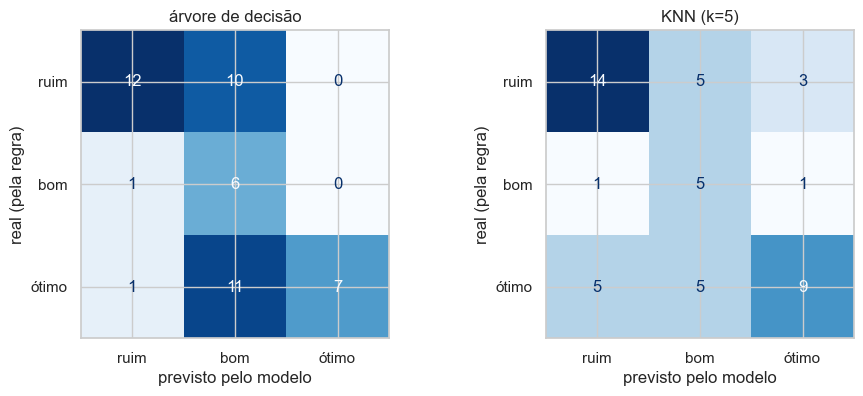

Árvore de decisão:
               precision    recall  f1-score   support

        ruim       0.86      0.55      0.67        22
         bom       0.22      0.86      0.35         7
       ótimo       1.00      0.37      0.54        19

    accuracy                           0.52        48
   macro avg       0.69      0.59      0.52        48
weighted avg       0.82      0.52      0.57        48

KNN:
               precision    recall  f1-score   support

        ruim       0.70      0.64      0.67        22
         bom       0.33      0.71      0.45         7
       ótimo       0.69      0.47      0.56        19

    accuracy                           0.58        48
   macro avg       0.58      0.61      0.56        48
weighted avg       0.64      0.58      0.59        48



In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, nome in zip(axs, ["árvore de decisão", "KNN (k=5)"]):
    ConfusionMatrixDisplay.from_predictions(y_te, modelos[nome].predict(X_te), labels=CLASSES, ax=ax, colorbar=False, cmap="Blues")
    ax.set(title=nome, xlabel="previsto pelo modelo", ylabel="real (pela regra)")
plt.show()

print("Árvore de decisão:\n", classification_report(y_te, modelos["árvore de decisão"].predict(X_te), labels=CLASSES, zero_division=0))
print("KNN:\n", classification_report(y_te, modelos["KNN (k=5)"].predict(X_te), labels=CLASSES, zero_division=0))

Nas matrizes, as linhas mostram a classe segundo a regra e as colunas mostram o que o modelo previu, então a diagonal são os acertos.

O principal erro da árvore é rebaixar horas ótimas para boas: 11 das 19 horas ótimas foram previstas como boas. Ela quase nunca confundiu ótimo com ruim (só uma vez), então o erro costuma ser de um nível só. Ela também classificou 10 horas ruins como boas. Quando a árvore diz que uma hora é ótima ela sempre acerta, mas só encontrou 7 das 19 horas ótimas. O KNN acertou mais horas ótimas (9), mas em 5 casos confundiu ótimo com ruim, que é um erro mais grave para quem vai surfar.

A árvore rebaixa as horas ótimas porque, no treino, quase todas elas tinham vento de até 19 km/h. No teste, muitas horas ótimas têm vento entre 20 e 22 km/h, compensado pela onda maior e pela meia-maré, uma combinação que quase não apareceu no treino.

In [10]:
grupos = df["datahora"].dt.date
cv = LeaveOneGroupOut()
resumo = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X, y, groups=grupos, cv=cv,
                       scoring=["accuracy", "balanced_accuracy", "f1_macro"])
    resumo.append({
        "modelo": nome,
        "acurácia": f"{r['test_accuracy'].mean():.2f} ± {r['test_accuracy'].std():.2f}",
        "acurácia balanceada": f"{r['test_balanced_accuracy'].mean():.2f} ± {r['test_balanced_accuracy'].std():.2f}",
        "F1 macro": f"{r['test_f1_macro'].mean():.2f} ± {r['test_f1_macro'].std():.2f}",
    })
pd.DataFrame(resumo).set_index("modelo")

,acurácia,acurácia balanceada,F1 macro
modelo,,,
baseline (sempre 'ruim'),0.67 ± 0.19,0.40 ± 0.08,0.33 ± 0.12
árvore de decisão,0.67 ± 0.10,0.68 ± 0.12,0.58 ± 0.10
KNN (k=5),0.76 ± 0.11,0.55 ± 0.15,0.52 ± 0.17


Com só 48 horas no teste, o resultado depende muito de quais dias ficaram de fora. Por isso também fiz uma validação cruzada deixando um dia de fora de cada vez: o modelo treina com 6 dias e é testado no sétimo, e isso se repete 7 vezes, uma para cada dia. O valor depois do ± mostra quanto o resultado variou entre os dias, e ele variou bastante (entre 0,10 e 0,19), então qualquer número isolado aqui é pouco confiável.

Essa tabela também mostra bem o problema da acurácia. A árvore tem a mesma acurácia da referência (0,67), mas na acurácia balanceada a diferença fica clara: 0,68 contra 0,40. O KNN tem a maior acurácia (0,76), mas uma acurácia balanceada menor (0,55), porque acerta muito a classe ruim, que é a mais fácil, e erra mais as outras. Pela acurácia balanceada, a árvore foi o melhor modelo.

In [11]:
# Quão funda deve ser a árvore? Mais profundidade = mais perguntas = mais capacidade de decorar.
comparacao = []
for prof in [2, 3, 4, 5, 6, 8, None]:
    arv = DecisionTreeClassifier(max_depth=prof, class_weight="balanced", random_state=42)
    cv_bal = cross_validate(arv, X, y, groups=grupos, cv=cv, scoring="balanced_accuracy")["test_score"]
    comparacao.append({
        "profundidade máxima": "sem limite" if prof is None else prof,
        "acerto nos próprios dados de treino": round(arv.fit(X, y).score(X, y), 2),
        "acurácia balanceada (dia de fora)": round(cv_bal.mean(), 2),
    })
pd.DataFrame(comparacao).set_index("profundidade máxima")

,acerto nos próprios dados de treino,acurácia balanceada (dia de fora)
profundidade máxima,,
2,0.72,0.66
3,0.67,0.62
4,0.88,0.68
5,0.90,0.66
6,0.95,0.63
8,0.99,0.65
sem limite,1.00,0.65


Quanto mais funda a árvore, mais ela acerta os próprios dados de treino, chegando a 100% sem limite de profundidade. Mas o acerto nos dias que ela não viu não melhora junto, e até piora. Isso é sobreajuste: a árvore funda passa a decorar as horas desta semana em vez de aprender um padrão. A profundidade 4 teve o melhor resultado nos dias de fora (0,68), por isso foi a escolhida. Uma árvore sem limite acertando 100% não estaria prevendo o mar, estaria só decorando a regra e as horas específicas da semana.

## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

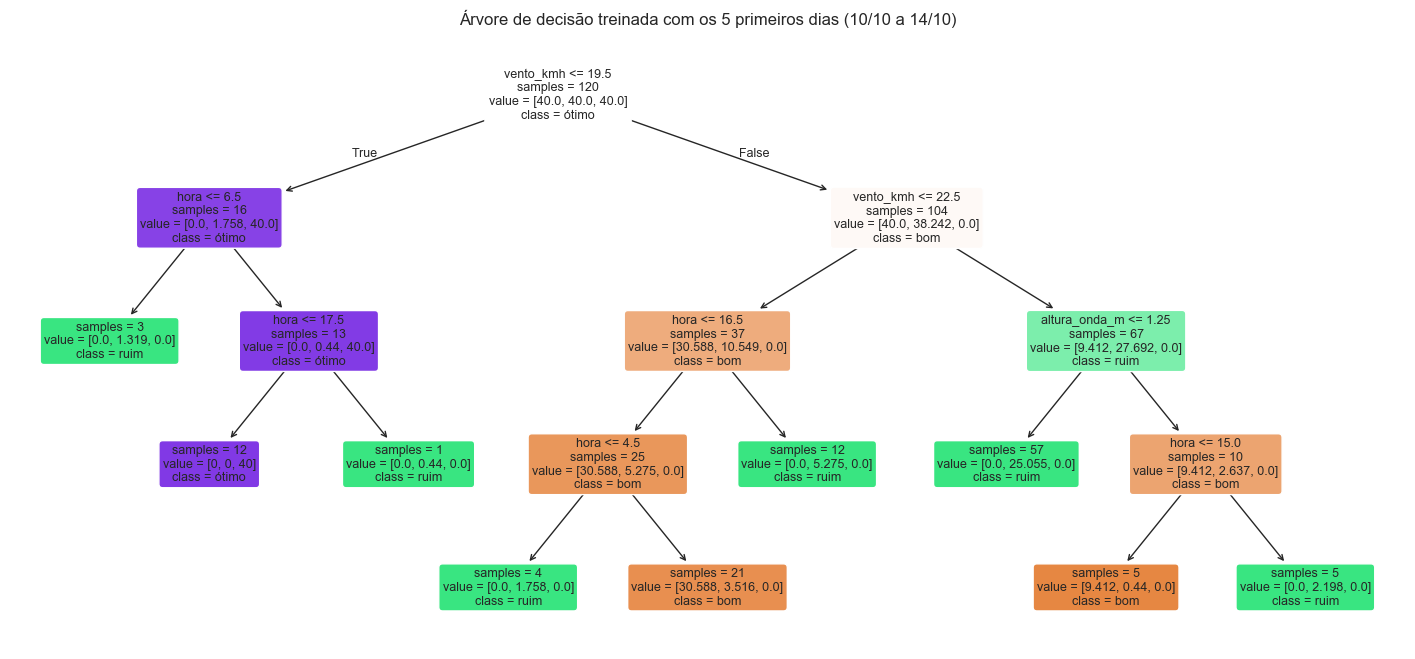

In [12]:
arvore = modelos["árvore de decisão"]
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(arvore, feature_names=X.columns, class_names=list(arvore.classes_), filled=True,
          rounded=True, impurity=False, proportion=False, fontsize=9, ax=ax)
ax.set_title(f"Árvore de decisão treinada com os 5 primeiros dias ({dias[0]:%d/%m} a {dias[4]:%d/%m})")
plt.show()

Cada caixa da árvore faz uma pergunta. Se a resposta for sim, o caminho segue para a esquerda, e se for não, para a direita, até chegar nas caixas de baixo, que dão a classe. Os números em value aparecem quebrados por causa do class_weight="balanced", que muda o peso de cada classe.

Os cortes que a árvore encontrou são praticamente os limites da minha regra. Ela perguntou se o vento é menor que 19,5 km/h e que 22,5 km/h, e a regra usa 19 e 22. Perguntou se a onda é menor que 1,25 m, e a regra usa 1,3 m. E usou a hora para separar o dia da noite, com cortes perto das 4h30 e das 17h30, enquanto a regra considera dia das 5h às 17h. Sem conhecer a regra, só olhando os exemplos, o modelo chegou nos mesmos números. Isso confirma que ele aprendeu a regra, e também que ele aprendeu só a regra. A única parte que ficou de fora foi a maré: com no máximo 4 perguntas e poucos exemplos, não sobrou espaço para o critério da meia-maré, que vale só 1 ponto.

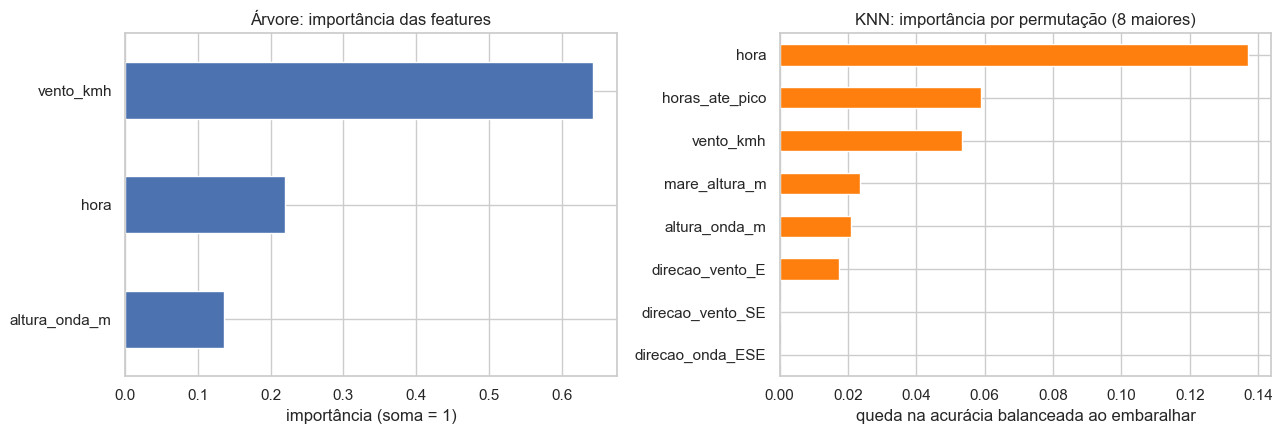

In [13]:
imp_arvore = pd.Series(arvore.feature_importances_, index=X.columns)
perm = permutation_importance(modelos["KNN (k=5)"], X_te, y_te, scoring="balanced_accuracy", n_repeats=30, random_state=42)
imp_knn = pd.Series(perm.importances_mean, index=X.columns)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
imp_arvore[imp_arvore > 0].sort_values().plot(kind="barh", ax=axs[0])
axs[0].set(title="Árvore: importância das features", xlabel="importância (soma = 1)")
imp_knn.sort_values().tail(8).plot(kind="barh", ax=axs[1], color="tab:orange")
axs[1].set(title="KNN: importância por permutação (8 maiores)", xlabel="queda na acurácia balanceada ao embaralhar")
plt.tight_layout()
plt.show()

Para a árvore, o vento foi a variável mais importante, com cerca de 65% da importância, seguido pela hora, que separa o dia da noite, e pela onda. Na minha regra, a onda pesa mais que o vento, mas no treino a onda variou pouco (ficou quase sempre entre 1,0 e 1,2 m até quarta), então o vento acabou sendo o que mais separou as classes.

Para o KNN, a hora foi a mais importante, depois as horas até o pico da maré e o vento. Isso faz sentido, porque a hora decide sozinha se a hora é de noite, e a noite responde por quase metade das classes.

Em geral, o resultado bate com a intuição: vento, hora e onda aparecem no topo, e são as variáveis da regra. As direções do vento e da onda quase não importaram, o que também faz sentido, já que elas mal variaram na semana.

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

### Como cheguei na resposta

Usei a árvore, que teve o melhor resultado na acurácia balanceada, treinada de novo com os 7 dias. Para cada hora, calculei uma nota de 0 a 1, somando a probabilidade de ser ótima com metade da probabilidade de ser boa. Depois ordenei as horas com luz do dia por essa nota e, em caso de empate, pela maior onda e pelo menor vento.

In [14]:
# Modelo final: a árvore, retreinada com os 7 dias inteiros.
final = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42).fit(X, y)
proba = pd.DataFrame(final.predict_proba(X), columns=final.classes_)

df["previsto"] = final.predict(X)
df["nota"] = proba["bom"] * 0.5 + proba["ótimo"] * 1.0   # 0 = ruim, 1 = ótimo com certeza
print(f"O modelo concorda com a regra em {(df['previsto'] == df['condicao']).mean():.0%} das horas.")

ranking = (df[df["luz_do_dia"]]
           .sort_values(["nota", "altura_onda_m", "vento_kmh"], ascending=[False, False, True])
           [["datahora", "dia_semana", "altura_onda_m", "vento_kmh", "direcao_vento", "mare_altura_m", "mare_estado", "previsto", "nota"]])
ranking.head(10).round({"mare_altura_m": 2, "nota": 2})

O modelo concorda com a regra em 88% das horas.


,datahora,dia_semana,altura_onda_m,vento_kmh,direcao_vento,mare_altura_m,mare_estado,previsto,nota
109,2026-10-14 13:00:00,qua,1.4,16.0,ESE,0.61,subindo,ótimo,1.0
108,2026-10-14 12:00:00,qua,1.4,17.0,E,0.67,descendo,ótimo,1.0
107,2026-10-14 11:00:00,qua,1.4,18.0,E,0.94,descendo,ótimo,1.0
110,2026-10-14 14:00:00,qua,1.4,18.0,ESE,0.75,subindo,ótimo,1.0
106,2026-10-14 10:00:00,qua,1.4,19.0,ENE,1.34,descendo,ótimo,1.0
111,2026-10-14 15:00:00,qua,1.4,19.0,E,1.07,subindo,ótimo,1.0
112,2026-10-14 16:00:00,qua,1.4,19.0,E,1.48,subindo,ótimo,1.0
113,2026-10-14 17:00:00,qua,1.4,19.0,E,1.86,subindo,ótimo,1.0
126,2026-10-15 06:00:00,qui,1.4,19.0,E,1.94,subindo,ótimo,1.0
85,2026-10-13 13:00:00,ter,1.3,19.0,ESE,0.57,subindo,ótimo,1.0


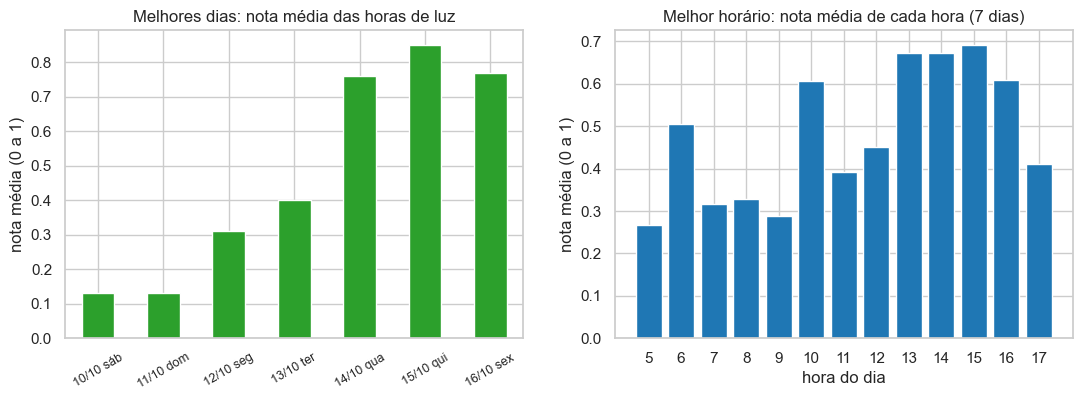

,horas_otimas,horas_boas,nota_media,onda_media,vento_medio
dia,,,,,
15/10 qui,11,2,0.85,1.33,20.08
16/10 sex,9,3,0.77,1.27,20.38
14/10 qua,8,4,0.76,1.37,19.46
13/10 ter,4,3,0.40,1.23,21.23
12/10 seg,0,9,0.31,1.22,22.85
11/10 dom,0,4,0.13,0.99,23.77
10/10 sáb,0,4,0.13,1.07,22.62


In [15]:
dia_label = df["datahora"].dt.strftime("%d/%m ") + df["dia_semana"]
de_dia = df[df["luz_do_dia"]]
por_dia = (de_dia.assign(dia=dia_label)
           .groupby("dia").agg(horas_otimas=("previsto", lambda s: (s == "ótimo").sum()),
                               horas_boas=("previsto", lambda s: (s == "bom").sum()),
                               nota_media=("nota", "mean"),
                               onda_media=("altura_onda_m", "mean"),
                               vento_medio=("vento_kmh", "mean"))
           .sort_values("nota_media", ascending=False).round(2))
por_hora = de_dia.groupby("hora")["nota"].mean()

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
por_dia["nota_media"].sort_index().plot(kind="bar", ax=axs[0], rot=30, color="tab:green")
axs[0].set(title="Melhores dias: nota média das horas de luz", xlabel="", ylabel="nota média (0 a 1)")
axs[0].tick_params(axis="x", labelsize=9)
axs[1].bar(por_hora.index, por_hora.values, color="tab:blue")
axs[1].set(title="Melhor horário: nota média de cada hora (7 dias)", xlabel="hora do dia", ylabel="nota média (0 a 1)", xticks=range(5, 18))
plt.show()
por_dia

**Leitura:**

- **Melhores dias:** de **quarta a sexta (14 a 16/10)**. **Quinta, 15/10** tem a maior nota média (11 horas ótimas, com onda de ~1,3 m o dia todo). **Quarta, 14/10** tem as **melhores horas individuais** da semana (10h às 17h, com onda de 1,4 m e o vento mais fraco, 16 km/h às 13h). O fim de semana (10 e 11/10) é o pior: onda pequena e vento forte.
- **Melhor horário, em média:** **das 13h às 16h** (nota média de ~0,67), quando o vento enfraquece. As piores horas de luz são as 5h e o começo da manhã (7h–9h), que coincide com o pico de vento das 9h.
- **Previsão do mar ou regra reescrita?** O modelo concorda com a regra em **88% das horas**. Ou seja, ~90% desta resposta **é a nossa regra**, só que reescrita em forma de árvore. A parte que é "previsão do mar" vem do **site**, que prevê onda e vento. O modelo não acrescenta conhecimento sobre o mar: ele só organiza essas previsões segundo o critério que *nós* definimos.

## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.

1. Felipe e Nicholas, nesta semana o melhor é vir entre quarta e sexta (14 a 16/10) e surfar no começo da tarde, entre 13h e 16h, com o melhor momento na quarta por volta das 13h (onda de 1,4 m e o vento mais fraco da semana), mas como o vento veio do mar o tempo todo, esperem um mar bom, e não excelente.

2. O modelo aprendeu a copiar a minha regra, então ele nunca vai ser melhor que ela. E a regra tem problemas: os limites que usei (1,3 m de onda, 19 km/h de vento, meia-maré) são chutes informados, tirados da escala Beaufort, de conhecimento geral de surf e da distribuição dos dados. Ninguém que surfa em João Pessoa validou esses números. A regra também ignora coisas que importam para a qualidade da onda, como o período da onda e como cada praia reage à direção de onde a onda vem.

Para melhorar, o ideal seria ter rótulos de verdade, por exemplo pedindo para surfistas locais darem nota para as sessões deles. Aí o modelo poderia aprender algo que eu não sei, em vez de só redescobrir a regra que eu escrevi.

3. Com 168 horas, não dá para tirar conclusões além desta semana. Cada dia da semana aparece uma vez só, a onda ficou entre 0,9 e 1,4 m e não teve nenhuma hora de vento terral. Se aparecer uma onda de 2 m ou um vento da terra, o modelo não sabe o que fazer, porque nunca viu isso. Na validação cruzada, o resultado também variou bastante de um dia para o outro (cerca de 0,12 para mais ou para menos), o que mostra que os números são instáveis.

4. O que falta é o histórico de onda e vento, já que o site só mostra os próximos 7 dias. Daria para resolver de dois jeitos: deixar o scrape.py rodando automaticamente todo dia durante um ano, guardando as previsões, ou usar bases históricas de modelos oceânicos (como as do Copernicus), que têm dados de onda e vento de vários anos. Com isso, daria para repetir a análise mês a mês e ver qual mês tem a melhor nota média.

Por enquanto, a única pista sobre o ano vem da maré de 2025: as marés mais fortes acontecem perto de março e setembro. Mas a maré sozinha não diz se vai ter onda boa.